# 04 — p5986 acoustic variance windows

p5986 acquisition:

- 12 passive PZT channels;
- 512 samples per waveform, 512 acquisitions per superframe, 10 superframes per file;
- nominal acoustic sampling frequency 2.5 MHz;
- **all acquisition slots are passive and retained**;
- window length = 5% of the mean p5986 seismic-cycle duration;
- 90% overlap; variance-only features.

No p5984 missing-acquisition fraction, first-slot removal, or multi-rate-stage assumption is reused.

Workflow Reference:

- Hulbert et al. (2019): moving-window variance, TTF, and shear-stress prediction baseline;
- Bolton et al. (2020): physical interpretation and constant-time/window-size checks for passive acoustic energy;
- Shreedharan et al. (2021): active-source P-wave amplitude/velocity comparison only; these are not available as p5986 passive features;
- Borate et al. (2024): hybrid passive/active PINN-RSF extension for future work, not part of this variance-only XGBoost baseline.


In [ ]:
# ===== Common setup: Google Drive path and output folder =====
from pathlib import Path
import os, json, re, math, glob, shutil, warnings
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as exc:
    print('Not running in Colab or Drive already mounted:', exc)

# Edit only when the Drive shortcut/folder is elsewhere.
P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
assert P5986_ROOT.exists(), (
    f'Cannot find p5986 folder: {P5986_ROOT}. '
    'Add a Drive shortcut or edit P5986_ROOT.'
)

MECH_DIR = P5986_ROOT / 'mechData'
AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(exist_ok=True, parents=True)
print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)


Mounted at /content/drive
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986


In [ ]:
# ===== Small HDF5 utilities =====
import h5py

def _as_array(x):
    x = np.asarray(x)
    if x.dtype == object:
        x = x.astype(str)
    return x

def save_dict_h5(path, data, attrs=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with h5py.File(path, 'w') as f:
        for k, v in data.items():
            arr = _as_array(v)
            if arr.dtype.kind in {'U', 'O'}:
                dt = h5py.string_dtype(encoding='utf-8')
                f.create_dataset(k, data=arr.astype(str), dtype=dt)
            else:
                f.create_dataset(k, data=arr, compression='gzip', compression_opts=4, shuffle=True)
        if attrs:
            for k, v in attrs.items():
                f.attrs[k] = json.dumps(v) if isinstance(v, (dict, list, tuple)) else v
    print('saved:', path)

def load_h5_to_dict(path):
    out = {}
    with h5py.File(path, 'r') as f:
        for k in f.keys():
            out[k] = f[k][()]
            if getattr(out[k], 'dtype', None) is not None and out[k].dtype.kind == 'S':
                out[k] = out[k].astype(str)
    return out

def load_h5_to_df(path):
    d = load_h5_to_dict(path)
    return pd.DataFrame({k: np.ravel(v) for k, v in d.items() if np.asarray(v).ndim <= 1})


# ===== MATLAB .mat loader that works for v7 and v7.3 =====
import scipy.io as sio
import h5py

def loadmat_any(path):
    path = Path(path)
    try:
        return {k: v for k, v in sio.loadmat(path, squeeze_me=True, struct_as_record=False).items() if not k.startswith('__')}
    except NotImplementedError:
        out = {}
        with h5py.File(path, 'r') as f:
            def read_obj(obj):
                arr = obj[()]
                # MATLAB v7.3 char arrays may be uint16 codes
                if getattr(arr, 'dtype', None) is not None and arr.dtype.kind in {'u','i'} and arr.ndim >= 1 and arr.size < 10000:
                    try:
                        return ''.join(chr(int(x)) for x in arr.ravel() if int(x) != 0)
                    except Exception:
                        return arr
                return arr
            def walk(g, prefix=''):
                for k, obj in g.items():
                    name = f'{prefix}/{k}' if prefix else k
                    if isinstance(obj, h5py.Dataset):
                        out[name] = read_obj(obj)
                    else:
                        walk(obj, name)
            walk(f)
        return out

def scalar(x, default=None):
    if x is None:
        return default
    arr = np.asarray(x)
    if arr.size == 0:
        return default
    try:
        return arr.item()
    except Exception:
        return arr.ravel()[0]

def sorted_wf_files(run_dir):
    files = list(Path(run_dir).glob('WF_*.ac'))
    def number(p):
        m = re.search(r'WF_(\d+)\.ac$', p.name)
        return int(m.group(1)) if m else 10**18
    return sorted(files, key=number)


## 1. Load acoustic settings & sync


In [ ]:
AC_SETTINGS_FILE = MAT_DIR / 'p5986_run1.mat'
SYNC_FILE = AC_DIR / 'p5986_sync_run1.mat'
SYNC_CONVERTED_FILE = AC_DIR / 'p5986_sync_run1_converted.mat'  # optional fallback only
assert AC_SETTINGS_FILE.exists(), AC_SETTINGS_FILE
settings = loadmat_any(AC_SETTINGS_FILE)

Nsamples = int(scalar(settings.get('Nsamples')))
Ngap0 = int(scalar(settings.get('Ngap')))
numAcqs = int(scalar(settings.get('numAcqs')))
numFrames = int(scalar(settings.get('numFrames')))
channels2save = np.ravel(settings.get('channels2save'))
numCH = len(channels2save)
samplingFreq_MHz = float(scalar(settings.get('samplingFreq')))
Decimation = int(scalar(settings.get('Decimation'), 1) or 1)
fs_ac = samplingFreq_MHz * 1e6 / Decimation
numSFpfile = int(numFrames / 2)
numWFpSFpCH = int(numAcqs)
numWFpfilepCH = numSFpfile * numWFpSFpCH
numPointspfilepCH = numWFpfilepCH * Nsamples
print(dict(Nsamples=Nsamples, Ngap=Ngap0, numAcqs=numAcqs, numFrames=numFrames, numSFpfile=numSFpfile, numCH=numCH, fs_ac=fs_ac))

# 補防呆
channels2save = np.asarray(
    settings['channels2save'],
    dtype=int
).ravel()

assert Nsamples > 0
assert Ngap0 >= 0
assert numAcqs > 0
assert numFrames % 2 == 0
assert numCH > 0

numSFpfile = numFrames // 2
numWFpSFpCH = numAcqs
numWFpfilepCH = numSFpfile * numWFpSFpCH
numPointspfilepCH = numWFpfilepCH * Nsamples

expected_values_per_file = numPointspfilepCH * numCH
expected_bytes_per_file = (
    expected_values_per_file
    * np.dtype(np.int16).itemsize
)

print({
    'Nsamples': Nsamples,
    'Ngap_nominal': Ngap0,
    'numAcqs_per_superframe': numAcqs,
    'numSuperFrames_per_file': numSFpfile,
    'waveforms_per_file_per_channel': numWFpfilepCH,
    'samples_per_file_per_channel': numPointspfilepCH,
    'channels2save': channels2save.tolist(),
    'numCH': numCH,
    'fs_ac_nominal_hz': fs_ac,
    'expected_bytes_per_file': expected_bytes_per_file,
})


{'Nsamples': 512, 'Ngap': 100, 'numAcqs': 512, 'numFrames': 20, 'numSFpfile': 10, 'numCH': 12, 'fs_ac': 2500000.0}
{'Nsamples': 512, 'Ngap_nominal': 100, 'numAcqs_per_superframe': 512, 'numSuperFrames_per_file': 10, 'waveforms_per_file_per_channel': 5120, 'samples_per_file_per_channel': 2621440, 'channels2save': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], 'numCH': 12, 'fs_ac_nominal_hz': 2500000.0, 'expected_bytes_per_file': 62914560}


In [ ]:
# revised
# Time synchronization and acoustic clock validation

import numpy as np
import scipy.io as sio
import warnings
import re
from pathlib import Path

REQUIRE_SYNC = True

# 原始的 MATLAB 檔中, 只要這 9 個關鍵字
SYNC_WANTED_KEYS = [
    'runname',
    'acousticrun',
    'AcSettingsfile',
    'WF_path',
    'totalnumberoffiles',
    'acTime',
    'acPeriod',
    'ts',
    'ts_adjusted',
]

# Helper Functions 清洗舊的資料
def text_scalar(x):
    """Convert MATLAB scalar/string-like object to a clean Python string."""
    if x is None:
        return None

    if isinstance(x, str):
        return x.strip()

    arr = np.asarray(x)

    if arr.size == 0:
        return None

    if arr.dtype.kind in {'U', 'S'}:
        return ''.join(arr.astype(str).ravel()).strip()

    return str(arr.ravel()[0]).strip()


def load_sync_minimal(path):
    """
    Load only synchronization variables needed by this notebook.

    Loading selected variables avoids the duplicate-None warnings
    and avoids loading large mechanical arrays unnecessarily.
    """
    path = Path(path)

    try:
        raw = sio.loadmat(
            path,
            variable_names=SYNC_WANTED_KEYS, # 只讀上面列出的 9 個變數, save RAM
            squeeze_me=True,         # 把 1xN 的矩陣壓扁成 1D 陣列
            struct_as_record=False,
        )
        return {
            k: v
            for k, v in raw.items()
            if not k.startswith('__')
        }

    except NotImplementedError:
        # Fallback for MATLAB v7.3/HDF5 files.
        full = loadmat_any(path)
        return {
            k: full[k]
            for k in SYNC_WANTED_KEYS
            if k in full
        }


# ------------------------------------------------------------
# Load a valid sync file
# ------------------------------------------------------------
sync = {}
sync_path_used = None
load_errors = []

for candidate in [SYNC_FILE, SYNC_CONVERTED_FILE]:
    candidate = Path(candidate)

    if not candidate.exists():
        load_errors.append(f'{candidate}: file does not exist')
        continue

    try:
        candidate_sync = load_sync_minimal(candidate)

        if 'acTime' not in candidate_sync:
            raise KeyError('acTime is missing')

        if 'ts' not in candidate_sync and 'ts_adjusted' not in candidate_sync:
            raise KeyError('neither ts nor ts_adjusted is present')

        sync = candidate_sync
        sync_path_used = candidate
        break

    except Exception as exc:
        load_errors.append(f'{candidate}: {type(exc).__name__}: {exc}')


if not sync:
    message = (
        'No valid p5986 synchronization file was loaded.\n'
        + '\n'.join(load_errors)
    )

    if REQUIRE_SYNC:
        raise RuntimeError(message)
    else:
        warnings.warn(
            message
            + '\nOnly relative nominal acoustic time will be available.'
        )


print('Loaded sync:', sync_path_used)
print('sync keys:', sorted(sync.keys()))


# ------------------------------------------------------------
# Validate experiment identity(舊的有拿不是 p5986 的檔案)
# ------------------------------------------------------------
runname_sync = text_scalar(sync.get('runname'))
acousticrun_sync = text_scalar(sync.get('acousticrun'))
settings_name_sync = text_scalar(sync.get('AcSettingsfile'))
wf_path_sync = text_scalar(sync.get('WF_path'))

assert runname_sync == 'p5986', (
    f'Wrong experiment in sync file: runname={runname_sync!r}'
)

assert acousticrun_sync == 'run1', (
    f'Wrong acoustic run in sync file: acousticrun={acousticrun_sync!r}'
)

print('runname        =', runname_sync)
print('acousticrun    =', acousticrun_sync)
print('AcSettingsfile =', settings_name_sync)
print('WF_path        =', wf_path_sync)


# ------------------------------------------------------------
# Convert ts robustly to seconds/sample
# ------------------------------------------------------------
ts_key = 'ts' if 'ts' in sync else 'ts_adjusted'
ts_raw = float(scalar(sync[ts_key]))

nominal_ts_s = 1.0 / fs_ac

# Test both plausible interpretations and select the one
# consistent with the nominal 2.5 MHz sampling rate.
ts_candidates = {
    'seconds/sample': ts_raw,
    'microseconds/sample': ts_raw * 1e-6,
}

ts_unit, ts = min(
    ts_candidates.items(),
    key=lambda item: abs(item[1] - nominal_ts_s),
)

relative_ts_error = abs(ts - nominal_ts_s) / nominal_ts_s

if not np.isfinite(ts) or ts <= 0:
    raise ValueError(f'Invalid acoustic sample interval: {ts}')

if relative_ts_error > 0.01:
    raise ValueError(
        f'Sync ts is inconsistent with settings sampling frequency. '
        f'ts_raw={ts_raw}, interpreted ts={ts} s, '
        f'nominal={nominal_ts_s} s.'
    )

fs_ac_adjusted = 1.0 / ts

print('ts source key         =', ts_key)
print('ts raw value          =', ts_raw)
print('ts interpreted unit   =', ts_unit)
print('ts                    =', ts, 's/sample')
print('adjusted acoustic fs  =', fs_ac_adjusted, 'Hz')
print('nominal acoustic fs   =', fs_ac, 'Hz')
print('relative clock change =', relative_ts_error)


# ------------------------------------------------------------
# Validate acTime
# ------------------------------------------------------------
acTime = np.ravel(
    np.asarray(sync['acTime'], dtype=np.float64)
)

# 檢查 1：波形數量太少？
if acTime.size < 2:
    raise ValueError('acTime contains fewer than two entries.')

# 檢查 2：有沒有奇怪的空值 (NaN) 或無限大？
if not np.all(np.isfinite(acTime)):
    raise ValueError('acTime contains NaN or infinite values.')

# 檢查 3：時間有沒有倒流？ (後面的點必須大於前面的點，diff 必須大於 0)
if not np.all(np.diff(acTime) > 0):
    raise ValueError('acTime is not strictly increasing.')

# ------------------------------------------------------------
# Validate WF-file count and acTime length
# ------------------------------------------------------------

# Count the WF files that actually exist on disk.
wf_files_sync_check = sorted_wf_files(RUN1_DIR)
actual_nfiles = len(wf_files_sync_check)

if actual_nfiles == 0:
    raise FileNotFoundError(
        f'No WF_*.ac files were found in {RUN1_DIR}.'
    )

num_wf_per_file = int(numWFpfilepCH)

if num_wf_per_file <= 0:
    raise ValueError(
        f'Invalid numWFpfilepCH={numWFpfilepCH}.'
    )

# Infer the required number of files independently from acTime.
nfiles_from_acTime, remainder = divmod(
    len(acTime),
    num_wf_per_file,
)

if remainder != 0:
    raise ValueError(
        f'acTime length {len(acTime)} is not divisible by '
        f'numWFpfilepCH={num_wf_per_file}. '
        f'Remainder={remainder}.'
    )

# The acoustic timestamps and actual WF files must agree.
if nfiles_from_acTime != actual_nfiles:
    raise ValueError(
        f'WF file-count mismatch: '
        f'acTime implies {nfiles_from_acTime} files, '
        f'but {actual_nfiles} WF files were found in '
        f'{RUN1_DIR}.'
    )

# totalnumberoffiles is optional because it is absent from some
# versions of p5986_sync_run1.mat.
sync_total_raw = sync.get('totalnumberoffiles')

if (
    sync_total_raw is not None
    and np.asarray(sync_total_raw).size > 0
):
    metadata_nfiles = int(scalar(sync_total_raw))

    if metadata_nfiles != actual_nfiles:
        raise ValueError(
            f'totalnumberoffiles mismatch: '
            f'sync metadata={metadata_nfiles}, '
            f'actual WF files={actual_nfiles}.'
        )

    nfiles_source = 'sync totalnumberoffiles + actual WF files'

else:
    metadata_nfiles = None
    nfiles_source = 'actual WF files and acTime'

    warnings.warn(
        'totalnumberoffiles is absent from the synchronization '
        'file. The file count was validated using the actual '
        'WF_*.ac files and len(acTime).'
    )

# Use the physically observed file count downstream.
sync_nfiles = actual_nfiles
expected_acTime_length = sync_nfiles * num_wf_per_file

# This should already be guaranteed by the checks above,
# but retain an explicit final assertion.
if len(acTime) != expected_acTime_length:
    raise ValueError(
        f'acTime length mismatch: len(acTime)={len(acTime)}, '
        f'expected={sync_nfiles} × {num_wf_per_file} '
        f'= {expected_acTime_length}.'
    )

print('WF-file count source       =', nfiles_source)
print('actual WF files            =', actual_nfiles)
print('files implied by acTime    =', nfiles_from_acTime)
print('sync metadata file count   =', metadata_nfiles)
print('expected acTime length     =', expected_acTime_length)


# ------------------------------------------------------------
# Acquisition-period diagnostics
# ------------------------------------------------------------
ac_dt = np.diff(acTime)
ac_period_s = float(np.median(ac_dt))
ac_period_us = ac_period_s * 1e6

samples_per_acquisition = ac_period_s / ts
gap_samples_float = samples_per_acquisition - Nsamples
gap_duration_s = ac_period_s - Nsamples * ts

print('number of sync files       =', sync_nfiles)
print('len(acTime)                =', len(acTime))
print('acTime range               =', (acTime[0], acTime[-1]))
print('median acquisition period  =', ac_period_s, 's')
print('median acquisition period  =', ac_period_us, 'us')
print('samples per acquisition    =', samples_per_acquisition)
print('effective gap in samples   =', gap_samples_float)
print('effective gap duration     =', gap_duration_s, 's')
print('nominal Ngap setting       =', Ngap0)
print('std(diff(acTime))          =', np.std(ac_dt), 's')


# Do not force the fractional gap into an integer for timing.
Ngap = Ngap0

if abs(gap_samples_float - Ngap0) > 2:
    warnings.warn(
        f'Effective gap ({gap_samples_float:.6f} samples) is '
        f'inconsistent with nominal Ngap={Ngap0}.'
    )

print(
    'Timing policy: use acTime for each waveform start and ts for '
    'within-waveform samples; do not construct absolute time using '
    'an integer Ngap.'
)


Loaded sync: /content/drive/MyDrive/MLStressDrop/p5986/acData/p5986_sync_run1.mat
sync keys: ['AcSettingsfile', 'WF_path', 'acTime', 'acousticrun', 'runname', 'ts_adjusted']
runname        = p5986
acousticrun    = run1
AcSettingsfile = p5986_run1.mat
WF_path        = run1/WF_
ts source key         = ts_adjusted
ts raw value          = 0.4000621670105896
ts interpreted unit   = microseconds/sample
ts                    = 4.000621670105896e-07 s/sample
adjusted acoustic fs  = 2499611.5165609503 Hz
nominal acoustic fs   = 2500000.0 Hz
relative clock change = 0.00015541752647398448


/tmp/ipykernel_325/4105574985.py:276: UserWarning: totalnumberoffiles is absent from the synchronization file. The file count was validated using the actual WF_*.ac files and len(acTime).
  warnings.warn(


WF-file count source       = actual WF files and acTime
actual WF files            = 2922
files implied by acTime    = 2922
sync metadata file count   = None
expected acTime length     = 14960640
number of sync files       = 2922
len(acTime)                = 14960640
acTime range               = (np.float64(1075.1080783952384), np.float64(4741.034294044663))
median acquisition period  = 0.00024503807730980043 s
median acquisition period  = 245.03807730980043 us
samples per acquisition    = 612.5000000395296
effective gap in samples   = 100.5000000395296
effective gap duration     = 4.0206247800378566e-05 s
nominal Ngap setting       = 100
std(diff(acTime))          = 3.2844992158526836e-13 s
Timing policy: use acTime for each waveform start and ts for within-waveform samples; do not construct absolute time using an integer Ngap.


## 2. MATLAB-equivalent reshape and fully passive waveform extraction

Unlike p5984, p5986 has no active first slot. Every one of the 512 acquisitions in each superframe is retained and matched one-to-one to `acTime`.


In [ ]:
# revised
# Read WF_*.ac files and retain every acquisition slot because p5986 is fully passive, following the legacy MATLAB workflow.
# Important:
# - Do not construct physical time using integer Ngap.
# - acTime gives each waveform start time.
# - ts gives sample spacing within each waveform.

def wf_number(path):
    """Extract the one-based file number from WF_<n>.ac."""
    name = Path(path).name
    m = re.fullmatch(r'WF_(\d+)\.ac', name)

    if m is None:
        raise ValueError(f'Invalid acoustic filename: {name}')

    return int(m.group(1))


# This function 把硬碟裡排成一長串的一維資料，折疊回它原本在硬體記憶體裡的 3D 結構（點數 * 通道 * Superframe）。
def reshape_ac_file_like_matlab(
    path,
    numCH=numCH,
    numSFpfile=numSFpfile,
):
    """
    Read one WF_*.ac file and reproduce the MATLAB LoadAcFile layout.

    Returns
    -------
    x : ndarray, shape (numPointspfilepCH, numCH)
        Rows contain all stored samples, ordered by superframe and
        acquisition. Columns correspond to channels2save.
    """
    path = Path(path)

    expected_values = numPointspfilepCH * numCH
    expected_bytes = expected_values * np.dtype('<i2').itemsize

    actual_bytes = path.stat().st_size

    if actual_bytes != expected_bytes:
        raise ValueError(
            f'{path.name}: unexpected file size. '
            f'found={actual_bytes:,} bytes, '
            f'expected={expected_bytes:,} bytes.'
        )

    raw = np.fromfile(path, dtype='<i2')

    if raw.size != expected_values:
        raise ValueError(
            f'{path.name}: unexpected number of int16 values. '
            f'found={raw.size:,}, expected={expected_values:,}.'
        )

    points_per_superframe_per_channel = (
        numWFpSFpCH * Nsamples
    )

    x = raw.reshape(
        (
            points_per_superframe_per_channel,
            numCH,
            numSFpfile,
        ),
        order='F',
    )

    x = np.transpose(x, (0, 2, 1))

    x = x.reshape(
        (numPointspfilepCH, numCH),
        order='F',
    )

    if x.shape != (numPointspfilepCH, numCH):
        raise RuntimeError(
            f'Unexpected reshaped array shape: {x.shape}'
        )

    return x


def extract_all_passive_waveforms(
    path,
    sensor_zero_based=0,
):
    """
    Extract one sensor from one WF_*.ac file.

    All acquisitions are retained. The p5986 settings and run notes identify all 12 channels and every acquisition slot as passive.

    Returns
    -------
    result : dict
        waveforms:
            float32 array with shape
            [numSFpfile * (numWFpSFpCH), Nsamples]

        waveform_start_s:
            mechanical-time start of each retained waveform.

        global_acquisition_index:
            zero-based acquisition index across the entire run.

        hardware_channel:
            one-based Verasonics receive-channel number.
    """
    path = Path(path)
    fnum = wf_number(path)

    if not 1 <= fnum <= sync_nfiles:
        raise ValueError(
            f'{path.name}: file number {fnum} is outside '
            f'the synchronized range 1–{sync_nfiles}.'
        )

    sensor = int(sensor_zero_based)

    if not 0 <= sensor < numCH:
        raise IndexError(
            f'sensor_zero_based={sensor} is outside '
            f'valid range 0–{numCH - 1}.'
        )

    x = reshape_ac_file_like_matlab(path)

    # Python sensor index -> Verasonics hardware channel.
    hardware_channel = int(channels2save[sensor])

    # One column contains:
    # [superframe, acquisition, sample]
    stream = x[:, sensor]

    expected_stream_length = (
        numSFpfile
        * numWFpSFpCH
        * Nsamples
    )

    if stream.size != expected_stream_length:
        raise ValueError(
            f'{path.name}: unexpected sensor stream length. '
            f'found={stream.size}, '
            f'expected={expected_stream_length}.'
        )

    # 確認資料長度正確後，把它折疊成 [Superframe, 波形數, 點數] 的 3D 結構
    all_waveforms = stream.reshape(
        numSFpfile,
        numWFpSFpCH,
        Nsamples,
    )

    # Locate the corresponding acquisition start times in acTime.
    first_global_acq = (
        (fnum - 1) * numWFpfilepCH
    )
    last_global_acq = (
        first_global_acq + numWFpfilepCH
    )

    starts_all = acTime[
        first_global_acq:last_global_acq
    ]

    if starts_all.size != numWFpfilepCH:
        raise ValueError(
            f'{path.name}: incomplete acTime slice. '
            f'found={starts_all.size}, '
            f'expected={numWFpfilepCH}.'
        )

    starts_all = starts_all.reshape(
        numSFpfile,
        numWFpSFpCH,
    )

    acquisition_indices_all = np.arange(
        first_global_acq,
        last_global_acq,
        dtype=np.int64,
    ).reshape(
        numSFpfile,
        numWFpSFpCH,
    )

    # p5986 is fully passive: retain acquisition index 0 and every other slot.
    retained_waveforms = all_waveforms
    retained_starts = starts_all
    retained_acquisition_indices = (
        acquisition_indices_all
    )

    retained_waveforms = retained_waveforms.reshape(
        -1,
        Nsamples,
    ).astype(
        np.float32,
        copy=False,
    )

    retained_starts = retained_starts.reshape(-1)
    retained_acquisition_indices = (
        retained_acquisition_indices.reshape(-1)
    )

    expected_retained_waveforms = (
        numSFpfile * (numWFpSFpCH)
    )

    expected_retained_samples = (
        expected_retained_waveforms * Nsamples
    )

    if retained_waveforms.shape != (
        expected_retained_waveforms,
        Nsamples,
    ):
        raise RuntimeError(
            f'Unexpected retained waveform shape: '
            f'{retained_waveforms.shape}'
        )

    return {
        'waveforms': retained_waveforms,
        'waveform_start_s': retained_starts,
        'global_acquisition_index': (
            retained_acquisition_indices
        ),
        'sensor_zero_based': sensor,
        'hardware_channel': hardware_channel,
        'file_number': fnum,
        'num_retained_waveforms': (
            expected_retained_waveforms
        ),
        'num_retained_samples': (
            expected_retained_samples
        ),
    }


# ------------------------------------------------------------
# Validate file numbering
# ------------------------------------------------------------
wf_files = sorted_wf_files(RUN1_DIR)

assert wf_files, (
    f'No WF_*.ac files found in {RUN1_DIR}'
)

wf_numbers = [wf_number(p) for p in wf_files]
expected_wf_numbers = list(
    range(1, sync_nfiles + 1)
)

if wf_numbers != expected_wf_numbers:
    missing = sorted(
        set(expected_wf_numbers) - set(wf_numbers)
    )
    extra = sorted(
        set(wf_numbers) - set(expected_wf_numbers)
    )

    raise ValueError(
        f'WF file numbering is not continuous. '
        f'Missing={missing[:20]}, extra={extra[:20]}'
    )


# ------------------------------------------------------------
# Test WF_1.ac
# ------------------------------------------------------------
test_file = wf_files[0]

test = extract_all_passive_waveforms(
    test_file,
    sensor_zero_based=0,
)

sample_offsets_s = (
    np.arange(Nsamples, dtype=np.float64) * ts
)

first_retained_time = (
    test['waveform_start_s'][0]
)

last_retained_time = (
    test['waveform_start_s'][-1]
    + sample_offsets_s[-1]
)

print('file:', test_file.name)
print(
    'Python sensor index:',
    test['sensor_zero_based'],
)
print(
    'Verasonics hardware channel:',
    test['hardware_channel'],
)
print(
    'retained waveform shape:',
    test['waveforms'].shape,
)
print(
    'retained waveforms:',
    test['num_retained_waveforms'],
)
print(
    'retained samples:',
    test['num_retained_samples'],
)
print(
    'global acquisition index range:',
    (
        test['global_acquisition_index'][0],
        test['global_acquisition_index'][-1],
    ),
)
print(
    'actual sample-time range:',
    (
        first_retained_time,
        last_retained_time,
    ),
)


file: WF_1.ac
Python sensor index: 0
Verasonics hardware channel: 1
retained waveform shape: (5120, 512)
retained waveforms: 5120
retained samples: 2621440
global acquisition index range: (np.int64(0), np.int64(5119))
actual sample-time range: (np.float64(1075.1080783952384), np.float64(1076.3626327446736))


## 3. Moving-window length for a single 10 μm/s run

Use 5% of the mean valid p5986 inter-event interval and a step equal to 10% of the window length (90% overlap). Set `WINDOW_SECONDS_OVERRIDE` only for an explicit sensitivity test.


In [ ]:
import pandas as pd
import numpy as np
import json
from pathlib import Path

EVENTS_CSV = OUT_DIR / '03_failure_picks_p5986_run1.csv'
LABELS_H5 = (
    OUT_DIR
    / '03_mechanical_labels_TTF_shear_stress_p5986_run1.h5'
)

assert EVENTS_CSV.exists(), (
    f'Run revised notebook 03 first: {EVENTS_CSV}'
)
assert LABELS_H5.exists(), (
    f'Run revised notebook 03 first: {LABELS_H5}'
)

events = pd.read_csv(EVENTS_CSV)

required_event_columns = {'failure_time_s', 'cycle_duration_to_next_failure_s'}
missing = required_event_columns.difference(events.columns)
if missing:
    raise KeyError(f'Missing event columns: {sorted(missing)}')

stable_cycles = events['cycle_duration_to_next_failure_s'].to_numpy(dtype=np.float64)
stable_cycles = stable_cycles[np.isfinite(stable_cycles) & (stable_cycles > 0)]

if len(stable_cycles) < 5:
    raise ValueError(
        'Too few same-stage cycles to estimate window length.'
    )

mean_cycle_s = float(np.mean(stable_cycles))
median_cycle_s = float(np.median(stable_cycles))

WINDOW_SECONDS_OVERRIDE = None

if WINDOW_SECONDS_OVERRIDE is None:
    WINDOW_SECONDS = 0.05 * mean_cycle_s
else:
    WINDOW_SECONDS = float(WINDOW_SECONDS_OVERRIDE)

# Millisecond precision is more than enough relative to 2.5 MHz AE data,
# and makes output filenames readable.
WINDOW_SECONDS = round(WINDOW_SECONDS, 3)
WINDOW_SECONDS = max(WINDOW_SECONDS, 0.005)

STEP_SECONDS = WINDOW_SECONDS * 0.10
HALF_WINDOW_SECONDS = WINDOW_SECONDS * 0.5

print('valid p5986 cycles:', len(stable_cycles))
print('mean cycle duration:', mean_cycle_s, 's')
print('median cycle duration:', median_cycle_s, 's')
print('WINDOW_SECONDS:', WINDOW_SECONDS, 's')
print('STEP_SECONDS:', STEP_SECONDS, 's')
print('overlap:', 1 - STEP_SECONDS / WINDOW_SECONDS)


valid p5986 cycles: 309
mean cycle duration: 2.7418284795229853 s
median cycle duration: 2.7170000005535258 s
WINDOW_SECONDS: 0.137 s
STEP_SECONDS: 0.013700000000000002 s
overlap: 0.9


## 4. Extracting Waveform-Level Sufficient Statistics for a Single Sensor

Instead of constructing a sample-level DataFrame, only the following metrics are preserved for each 512-point waveform:

- waveform center time
- sample count
- sum
- sum of squares

Subsequently, the population variance across any moving window can be computed efficiently via cumulative sums:

$$
\mathrm{Var}(x) = E[x^2] - E[x]^2
$$

This is consistent with the $1/N$ definition adopted in the paper.


In [ ]:
from scipy import signal
import h5py
import time
import shutil

SENSOR_ZERO_BASED = 9  # editable sensor choice (channel 10)
HIGH_PASS_HZ = None
MIN_COVERAGE_FRACTION = 0.75

with h5py.File(LABELS_H5, 'r') as f:
    mech_time = np.asarray(f['time_s'][:], dtype=np.float64)

analysis_start_s = float(mech_time[0])
analysis_end_s = float(mech_time[-1])

# Previous non-overlapping variance requires one extra window before
# the first output window.
acoustic_read_start_s = analysis_start_s - WINDOW_SECONDS
acoustic_read_end_s = analysis_end_s + WINDOW_SECONDS

file_first_acq = (
    np.arange(sync_nfiles, dtype=np.int64)
    * numWFpfilepCH
)
file_last_acq = file_first_acq + numWFpfilepCH - 1

file_start_s = acTime[file_first_acq]
file_end_s = (
    acTime[file_last_acq]
    + (Nsamples - 1) * ts
)

overlapping_files = (
    (file_end_s >= acoustic_read_start_s)
    & (file_start_s <= acoustic_read_end_s)
)

selected_file_indices = np.flatnonzero(overlapping_files)
selected_files = [
    wf_files[int(i)]
    for i in selected_file_indices
]

if not selected_files:
    raise ValueError('No acoustic files overlap the label interval.')

print(
    'selected files:',
    len(selected_files),
    selected_files[0].name,
    'to',
    selected_files[-1].name,
)

def read_one_sensor_waveforms_fast(path, sensor_zero_based=0):
    path = Path(path)
    sensor = int(sensor_zero_based)

    if not 0 <= sensor < numCH:
        raise IndexError(
            f'sensor {sensor} outside 0..{numCH - 1}'
        )

    points_per_sf_per_ch = numWFpSFpCH * Nsamples

    out = np.empty(
        (numSFpfile, numWFpSFpCH, Nsamples),
        dtype=np.int16,
    )

    with open(path, 'rb') as f:
        for sf in range(numSFpfile):
            value_offset = (
                (sf * numCH + sensor)
                * points_per_sf_per_ch
            )
            f.seek(value_offset * np.dtype('<i2').itemsize)

            block = np.fromfile(
                f,
                dtype='<i2',
                count=points_per_sf_per_ch,
            )

            if block.size != points_per_sf_per_ch:
                raise ValueError(
                    f'{path.name}: incomplete read at '
                    f'superframe {sf}.'
                )

            out[sf] = block.reshape(
                numWFpSFpCH,
                Nsamples,
            )

    # All p5986 acquisitions are passive; retain every slot.
    return out.reshape(-1, Nsamples)

# Validate fast reader against verified MATLAB-like reader.
reference = extract_all_passive_waveforms(
    selected_files[0],
    sensor_zero_based=SENSOR_ZERO_BASED,
)['waveforms']

fast = read_one_sensor_waveforms_fast(
    selected_files[0],
    sensor_zero_based=SENSOR_ZERO_BASED,
)

assert np.array_equal(reference, fast), (
    'Fast reader does not match verified reader.'
)
del reference, fast
print('fast reader validation passed')

sos = None
if HIGH_PASS_HZ is not None:
    if not 0 < HIGH_PASS_HZ < fs_ac_adjusted / 2:
        raise ValueError(f'Invalid HIGH_PASS_HZ={HIGH_PASS_HZ}')
    sos = signal.butter(
        2,
        HIGH_PASS_HZ,
        btype='highpass',
        fs=fs_ac_adjusted,
        output='sos',
    )

center_parts = []
count_parts = []
sum_parts = []
sumsq_parts = []
file_number_parts = []

start_clock = time.time()

for i, path in enumerate(selected_files, start=1):
    fnum = wf_number(path)

    waveforms = read_one_sensor_waveforms_fast(
        path,
        sensor_zero_based=SENSOR_ZERO_BASED,
    )

    first_global_acq = (fnum - 1) * numWFpfilepCH
    last_global_acq = first_global_acq + numWFpfilepCH

    starts = (
        acTime[first_global_acq:last_global_acq]
        .reshape(numSFpfile, numWFpSFpCH)
        .reshape(-1)
    )

    centers = starts + 0.5 * (Nsamples - 1) * ts

    keep = (
        (centers >= acoustic_read_start_s)
        & (centers <= acoustic_read_end_s)
    )

    if np.any(keep):
        centers = centers[keep]
        y = waveforms[keep].astype(np.float32, copy=False)

        if sos is not None:
            y = signal.sosfiltfilt(
                sos,
                y,
                axis=1,
            ).astype(np.float32, copy=False)

        waveform_sum = np.sum(
            y,
            axis=1,
            dtype=np.float64,
        )
        waveform_sumsq = np.einsum(
            'ij,ij->i',
            y,
            y,
            dtype=np.float64,
        )

        center_parts.append(centers.astype(np.float64))
        count_parts.append(
            np.full(len(centers), Nsamples, dtype=np.int32)
        )
        sum_parts.append(waveform_sum)
        sumsq_parts.append(waveform_sumsq)
        file_number_parts.append(
            np.full(len(centers), fnum, dtype=np.int32)
        )

        del y, waveform_sum, waveform_sumsq

    del waveforms

    if i == 1 or i % 20 == 0 or i == len(selected_files):
        elapsed = time.time() - start_clock
        seconds_per_file = elapsed / i
        eta_minutes = (
            seconds_per_file
            * (len(selected_files) - i)
            / 60
        )
        print(
            f'processed {i}/{len(selected_files)} '
            f'({path.name}); ETA≈{eta_minutes:.1f} min'
        )

waveform_time_s = np.concatenate(center_parts)
waveform_count = np.concatenate(count_parts).astype(np.int64)
waveform_sum = np.concatenate(sum_parts)
waveform_sumsq = np.concatenate(sumsq_parts)
waveform_file_number = np.concatenate(file_number_parts)

del (
    center_parts,
    count_parts,
    sum_parts,
    sumsq_parts,
    file_number_parts,
)

if not np.all(np.diff(waveform_time_s) > 0):
    order = np.argsort(waveform_time_s, kind='stable')
    waveform_time_s = waveform_time_s[order]
    waveform_count = waveform_count[order]
    waveform_sum = waveform_sum[order]
    waveform_sumsq = waveform_sumsq[order]
    waveform_file_number = waveform_file_number[order]

if not np.all(np.diff(waveform_time_s) > 0):
    raise ValueError('Waveform center time is not strictly increasing.')

print('retained waveform count:', len(waveform_time_s))
print('waveform time range:', (
    waveform_time_s[0],
    waveform_time_s[-1],
))


selected files: 678 WF_985.ac to WF_1662.ac
fast reader validation passed
processed 1/678 (WF_985.ac); ETA≈0.2 min
processed 20/678 (WF_1004.ac); ETA≈24.4 min
processed 40/678 (WF_1024.ac); ETA≈24.9 min
processed 60/678 (WF_1044.ac); ETA≈23.8 min
processed 80/678 (WF_1064.ac); ETA≈24.8 min
processed 100/678 (WF_1084.ac); ETA≈24.6 min
processed 120/678 (WF_1104.ac); ETA≈24.2 min
processed 140/678 (WF_1124.ac); ETA≈25.0 min
processed 160/678 (WF_1144.ac); ETA≈24.3 min
processed 180/678 (WF_1164.ac); ETA≈23.8 min
processed 200/678 (WF_1184.ac); ETA≈22.9 min
processed 220/678 (WF_1204.ac); ETA≈22.4 min
processed 240/678 (WF_1224.ac); ETA≈21.8 min
processed 260/678 (WF_1244.ac); ETA≈21.3 min
processed 280/678 (WF_1264.ac); ETA≈20.2 min
processed 300/678 (WF_1284.ac); ETA≈19.0 min
processed 320/678 (WF_1304.ac); ETA≈18.0 min
processed 340/678 (WF_1324.ac); ETA≈17.1 min
processed 360/678 (WF_1344.ac); ETA≈16.6 min
processed 380/678 (WF_1364.ac); ETA≈15.7 min
processed 400/678 (WF_1384.ac); ET

## 5.  Build 90%-overlap variance windows with cumulative sums


In [ ]:
cumulative_count = np.concatenate([
    np.array([0], dtype=np.int64),
    np.cumsum(waveform_count, dtype=np.int64),
])
cumulative_sum = np.concatenate([
    np.array([0.0]),
    np.cumsum(waveform_sum, dtype=np.float64),
])
cumulative_sumsq = np.concatenate([
    np.array([0.0]),
    np.cumsum(waveform_sumsq, dtype=np.float64),
])

def interval_statistics(start_s, end_s):
    '''Population statistics for many half-open intervals [start, end).'''
    start_s = np.asarray(start_s, dtype=np.float64)
    end_s = np.asarray(end_s, dtype=np.float64)

    if start_s.shape != end_s.shape:
        raise ValueError('start_s and end_s must have the same shape.')
    if np.any(end_s <= start_s):
        raise ValueError('Every interval must have positive duration.')

    left = np.searchsorted(
        waveform_time_s,
        start_s,
        side='left',
    )
    right = np.searchsorted(
        waveform_time_s,
        end_s,
        side='left',
    )

    n = cumulative_count[right] - cumulative_count[left]
    total = cumulative_sum[right] - cumulative_sum[left]
    total2 = cumulative_sumsq[right] - cumulative_sumsq[left]

    mean = np.full(len(start_s), np.nan, dtype=np.float64)
    variance = np.full(len(start_s), np.nan, dtype=np.float64)

    valid = n > 0
    mean[valid] = total[valid] / n[valid]
    variance[valid] = np.maximum(
        total2[valid] / n[valid] - mean[valid] ** 2,
        0.0,
    )

    duration = end_s - start_s
    coverage = n * ts / duration

    first_file = np.full(len(start_s), -1, dtype=np.int32)
    last_file = np.full(len(start_s), -1, dtype=np.int32)

    nonempty = right > left
    first_file[nonempty] = waveform_file_number[left[nonempty]]
    last_file[nonempty] = waveform_file_number[right[nonempty] - 1]

    return {
        'n_samples': n,
        'mean': mean,
        'variance': variance,
        'coverage_fraction': coverage,
        'wf_file_first': first_file,
        'wf_file_last': last_file,
    }

# Align the first start to the global step grid.
first_window_start_s = (
    np.ceil(analysis_start_s / STEP_SECONDS)
    * STEP_SECONDS
)
last_window_start_s = analysis_end_s - WINDOW_SECONDS

window_start_s = np.arange(
    first_window_start_s,
    last_window_start_s + 0.5 * STEP_SECONDS,
    STEP_SECONDS,
    dtype=np.float64,
)
window_end_s = window_start_s + WINDOW_SECONDS
window_center_s = window_start_s + HALF_WINDOW_SECONDS
window_mid_s = window_center_s

first_half = interval_statistics(
    window_start_s,
    window_mid_s,
)
second_half = interval_statistics(
    window_mid_s,
    window_end_s,
)
full_window = interval_statistics(
    window_start_s,
    window_end_s,
)
previous_nonoverlap = interval_statistics(
    window_start_s - WINDOW_SECONDS,
    window_start_s,
)

features = pd.DataFrame({
    'window_id': np.arange(len(window_start_s), dtype=np.int64),
    'window_start_s': window_start_s,
    'window_center_s': window_center_s,
    'window_end_s': window_end_s,
    'window_seconds': WINDOW_SECONDS,
    'step_seconds': STEP_SECONDS,
    'overlap_fraction': 0.90,

    # Main-text representation: two contiguous halves.
    'ae_var_first_half': first_half['variance'],
    'ae_var_second_half': second_half['variance'],

    # Full current window and previous adjacent non-overlapping window.
    'ae_var_full_window': full_window['variance'],
    'ae_var_previous_nonoverlap':
        previous_nonoverlap['variance'],

    'coverage_first_half':
        first_half['coverage_fraction'],
    'coverage_second_half':
        second_half['coverage_fraction'],
    'coverage_full_window':
        full_window['coverage_fraction'],
    'coverage_previous_nonoverlap':
        previous_nonoverlap['coverage_fraction'],

    'n_samples_full_window':
        full_window['n_samples'],
    'wf_file_first':
        full_window['wf_file_first'],
    'wf_file_last':
        full_window['wf_file_last'],
    'sensor_zero_based': SENSOR_ZERO_BASED,
    'hardware_channel':
        int(channels2save[SENSOR_ZERO_BASED]),
})

variance_columns = [
    'ae_var_first_half',
    'ae_var_second_half',
    'ae_var_full_window',
    'ae_var_previous_nonoverlap',
]
coverage_columns = [
    'coverage_first_half',
    'coverage_second_half',
    'coverage_full_window',
    'coverage_previous_nonoverlap',
]

valid_features = (
    np.isfinite(features[variance_columns]).all(axis=1)
    & (features[coverage_columns] >= MIN_COVERAGE_FRACTION).all(axis=1)
)

features = features.loc[valid_features].reset_index(drop=True)
features['window_id'] = np.arange(len(features), dtype=np.int64)

# Log variants remain acoustic-variance-only features and match
# the log-variance visualizations in the supplementary information.
positive_variance = features[variance_columns].to_numpy()
positive_values = positive_variance[positive_variance > 0]
variance_epsilon = (
    float(np.nanpercentile(positive_values, 0.1)) * 1e-3
    if len(positive_values)
    else 1e-12
)
variance_epsilon = max(variance_epsilon, 1e-12)

for column in variance_columns:
    features[f'log10_{column}'] = np.log10(
        features[column].to_numpy(dtype=np.float64)
        + variance_epsilon
    )

print('feature rows:', len(features))
print('feature time range:', (
    features['window_start_s'].min(),
    features['window_end_s'].max(),
))
print(
    'mean full-window coverage:',
    features['coverage_full_window'].mean(),
)
print('variance epsilon:', variance_epsilon)
display(features.head())


feature rows: 62034
feature time range: (2310.0118, 3160.00089999824)
mean full-window coverage: 0.8359183757229327
variance epsilon: 0.006996097192004562


,window_id,window_start_s,window_center_s,window_end_s,window_seconds,step_seconds,overlap_fraction,ae_var_first_half,ae_var_second_half,ae_var_full_window,...,coverage_previous_nonoverlap,n_samples_full_window,wf_file_first,wf_file_last,sensor_zero_based,hardware_channel,log10_ae_var_first_half,log10_ae_var_second_half,log10_ae_var_full_window,log10_ae_var_previous_nonoverlap
0,0,2310.0118,2310.0803,2310.1488,0.137,0.0137,0.9,15.881121,7.680244,11.788019,...,0.835774,286208,985,985,9,10,1.201072,0.885770,1.071698,0.912404
1,1,2310.0255,2310.0940,2310.1625,0.137,0.0137,0.9,15.917447,7.682247,11.807349,...,0.835774,286208,985,985,9,10,1.202064,0.885884,1.072410,0.913193
2,2,2310.0392,2310.1077,2310.1762,0.137,0.0137,0.9,7.896771,7.536696,7.718634,...,0.835774,286208,985,985,9,10,0.897834,0.877584,0.887934,1.081932
3,3,2310.0529,2310.1214,2310.1899,0.137,0.0137,0.9,7.849670,7.673022,7.769420,...,0.835774,286208,985,985,9,10,0.895238,0.885362,0.890779,1.080658
4,4,2310.0666,2310.1351,2310.2036,0.137,0.0137,0.9,7.595737,9.523173,8.564722,...,0.835774,286208,985,985,9,10,0.880970,0.979101,0.933068,1.085377


## 6. QC：variance evolution & mechanical shear stress


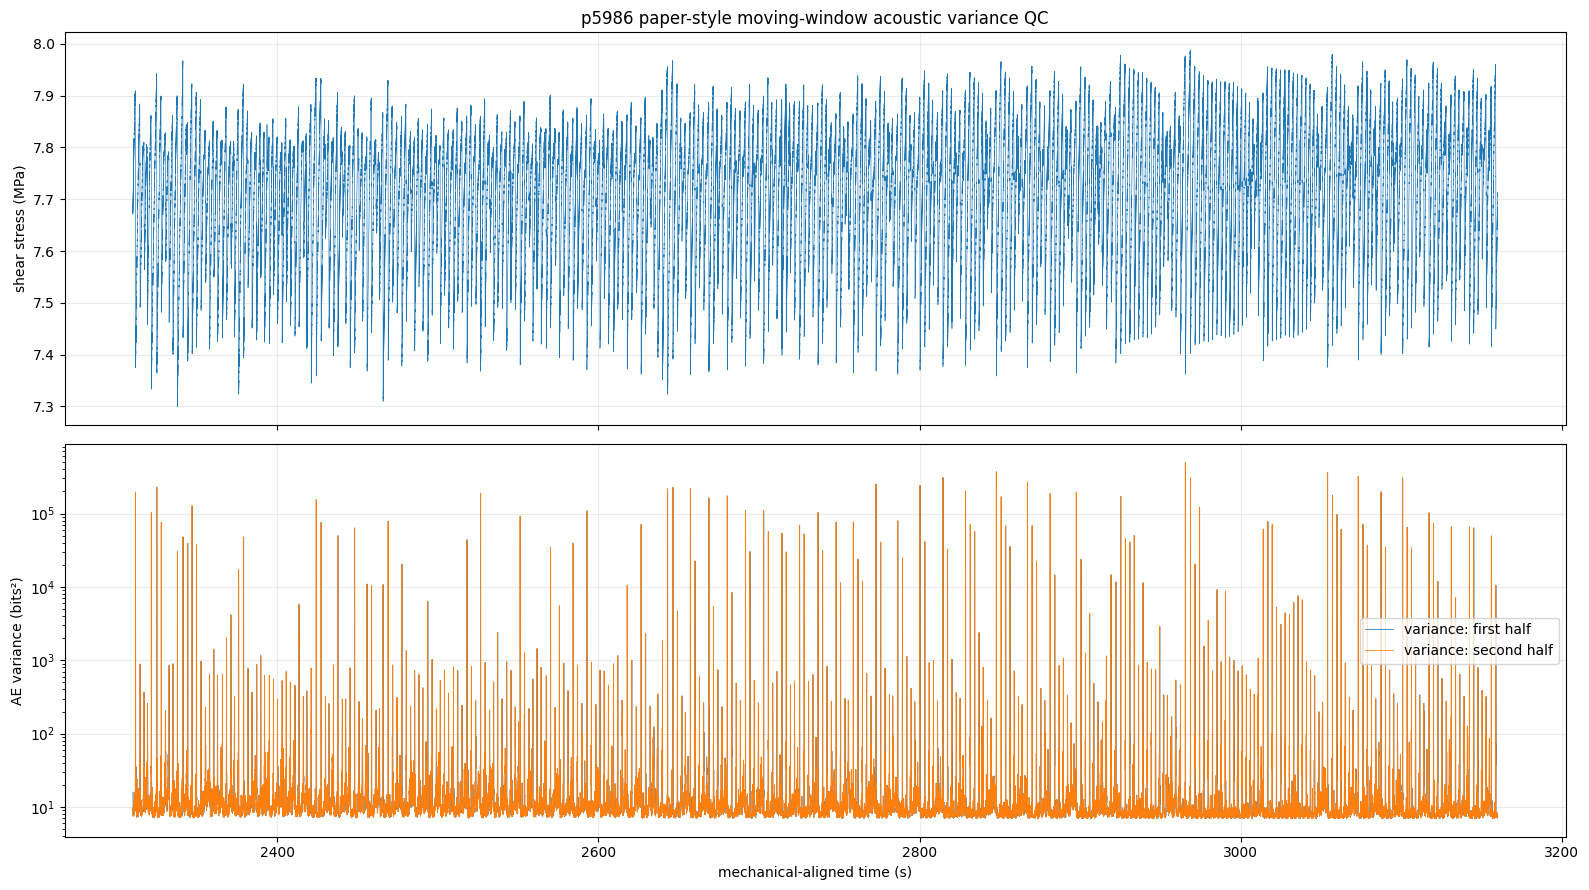

In [ ]:
import matplotlib.pyplot as plt

CAL_H5 = OUT_DIR / '02_mech_calibrated_p5986.h5'
assert CAL_H5.exists(), CAL_H5

with h5py.File(CAL_H5, 'r') as f:
    all_time = np.asarray(f['time_s'][:], dtype=np.float64)

    plot_start = float(features['window_start_s'].min())
    plot_end = float(features['window_end_s'].max())

    i0 = int(np.searchsorted(all_time, plot_start, side='left'))
    i1 = int(np.searchsorted(all_time, plot_end, side='right'))

    plot_time = all_time[i0:i1]
    plot_stress = np.asarray(
        f['shear_stress_mpa'][i0:i1],
        dtype=np.float64,
    )

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 9),
    sharex=True,
)

axes[0].plot(plot_time, plot_stress, lw=0.45)
axes[0].set_ylabel('shear stress (MPa)')
axes[0].set_title(
    'p5986 paper-style moving-window acoustic variance QC'
)
axes[0].grid(alpha=0.25)

axes[1].plot(
    features['window_center_s'],
    features['ae_var_first_half'],
    lw=0.55,
    label='variance: first half',
)
axes[1].plot(
    features['window_center_s'],
    features['ae_var_second_half'],
    lw=0.55,
    label='variance: second half',
)
axes[1].set_yscale('log')
axes[1].set_ylabel('AE variance (bits²)')
axes[1].set_xlabel('mechanical-aligned time (s)')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Basic invariants.
assert np.all(np.diff(features['window_center_s']) > 0)
assert (features[variance_columns] >= 0).all().all()
assert (
    features[coverage_columns] >= MIN_COVERAGE_FRACTION
).all().all()


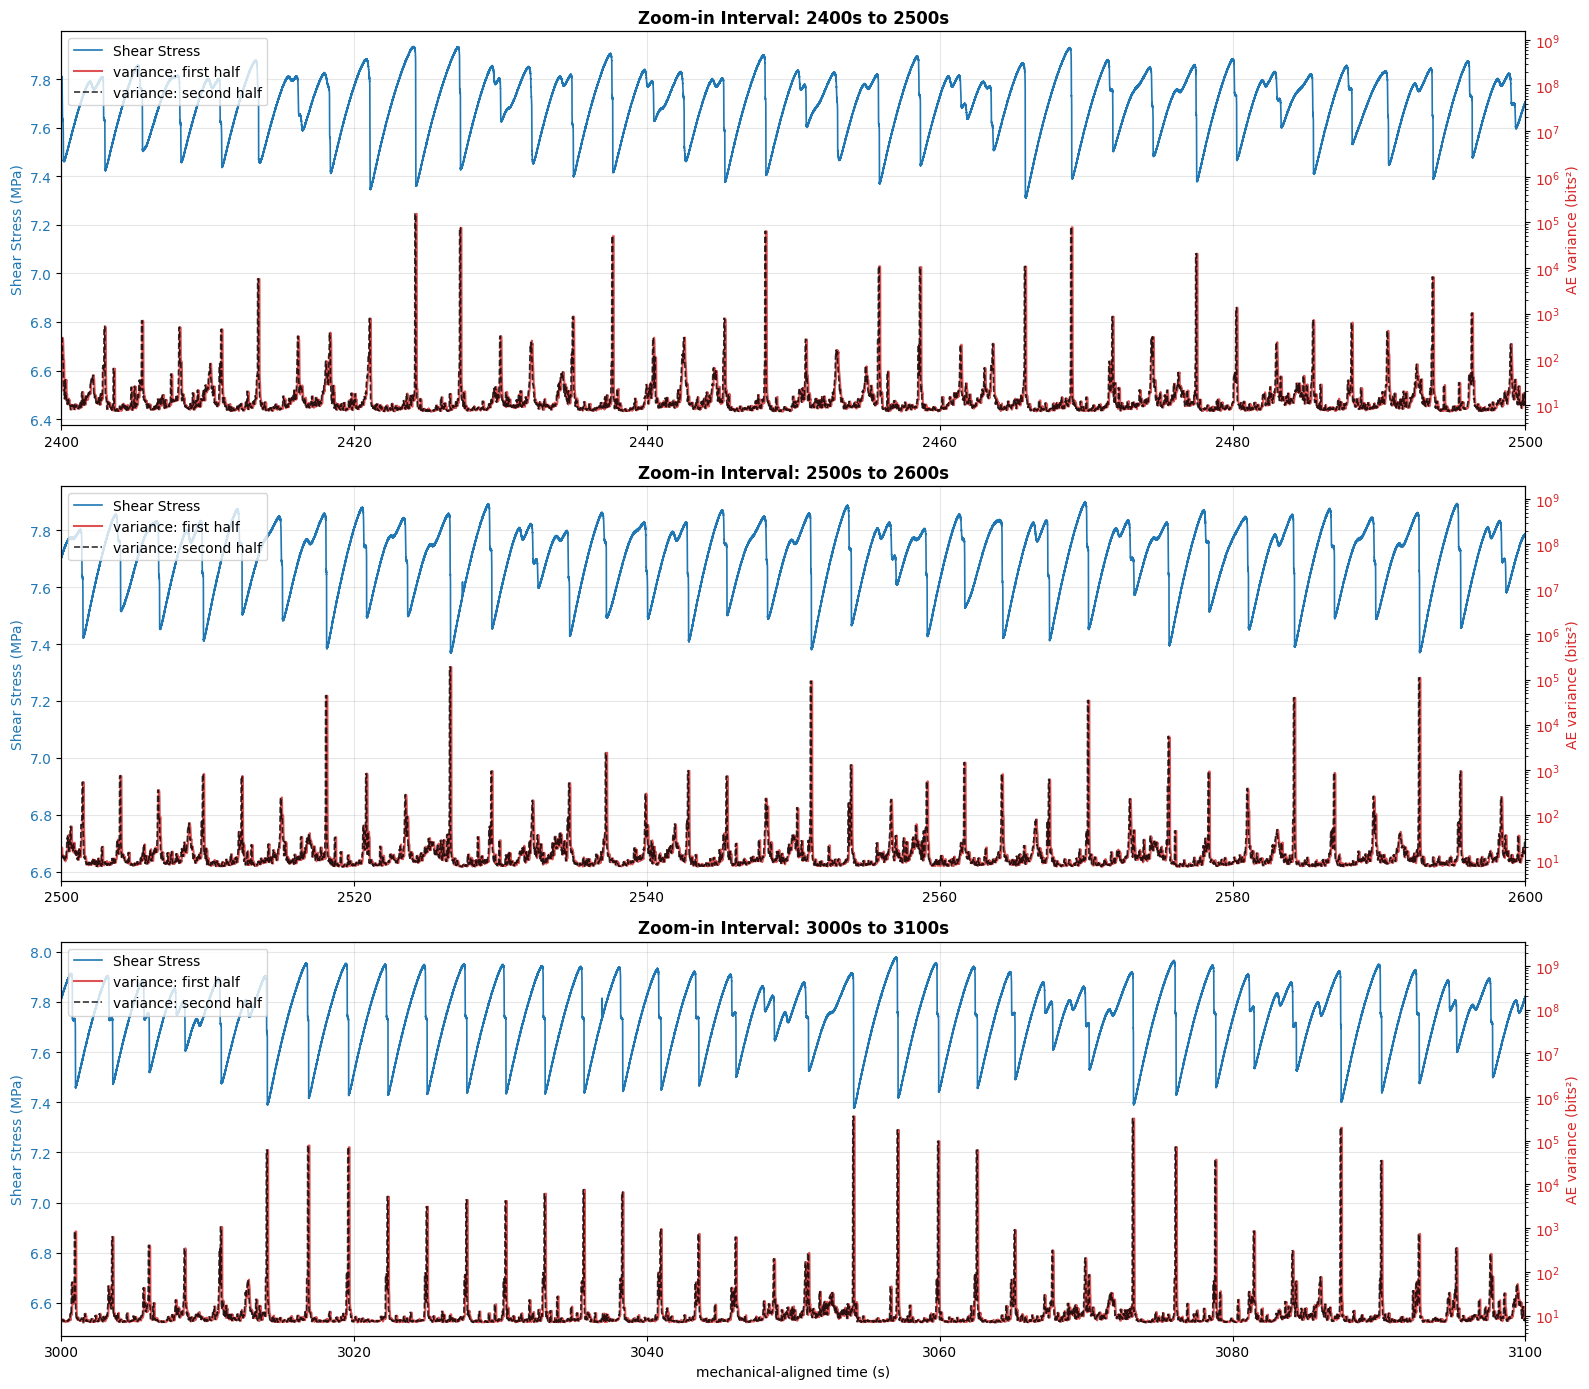

In [ ]:
# new plot update
import matplotlib.pyplot as plt
import numpy as np

# 定義想要 Zoom in 的三個時間區段
time_intervals = [(2400, 2500), (2500, 2600), (3000, 3100)]

# 建立 3 個子圖 (3 rows, 1 column)
fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=False)

for i, (t_start, t_end) in enumerate(time_intervals):
    ax1 = axes[i]

    # --- 1. 篩選該時間段的資料 ---
    # 應力資料篩選
    mask_stress = (plot_time >= t_start) & (plot_time <= t_end)
    t_stress_zoom = plot_time[mask_stress]
    stress_zoom = plot_stress[mask_stress]

    # 特徵資料篩選
    mask_var = (features['window_center_s'] >= t_start) & (features['window_center_s'] <= t_end)
    t_var_zoom = features.loc[mask_var, 'window_center_s']
    var1_zoom = features.loc[mask_var, 'ae_var_first_half']
    var2_zoom = features.loc[mask_var, 'ae_var_second_half']

    # --- 2. 繪製 Shear Stress (上半部) ---
    color_stress = 'tab:blue'
    ax1.plot(t_stress_zoom, stress_zoom, color=color_stress, lw=1.2, label='Shear Stress')
    ax1.set_ylabel('Shear Stress (MPa)', color=color_stress)
    ax1.tick_params(axis='y', labelcolor=color_stress)
    ax1.grid(alpha=0.3)
    ax1.set_xlim(t_start, t_end)

    # 強制將應力折線推向畫面上半部
    if len(stress_zoom) > 0:
        s_min, s_max = stress_zoom.min(), stress_zoom.max()
        s_range = s_max - s_min
        # 將 Y 軸下限往下延伸 1.5 倍的 range，讓應力圖形只佔據上半空間
        ax1.set_ylim(s_min - s_range * 1.5, s_max + s_range * 0.1)

    # --- 3. 繪製 AE Variance (下半部) ---
    ax2 = ax1.twinx()
    color_var1 = 'tab:red'
    color_var2 = 'k' # 使用黑色虛線來對比紅色實線

    # 將 first half 設為實線，second half 設為虛線，即使重合也能同時看見
    ax2.plot(t_var_zoom, var1_zoom, color=color_var1, lw=1.5, alpha=0.8, label='variance: first half')
    ax2.plot(t_var_zoom, var2_zoom, color=color_var2, lw=1.2, ls='--', alpha=0.8, label='variance: second half')

    ax2.set_ylabel('AE variance (bits²)', color=color_var1)
    ax2.set_yscale('log')
    ax2.tick_params(axis='y', labelcolor=color_var1)

    # 強制將 Variance 折線推向畫面下半部
    if len(var1_zoom) > 0:
        v_min = min(var1_zoom.min(), var2_zoom.min())
        v_max = max(var1_zoom.max(), var2_zoom.max())
        # Log scale 的延伸必須用乘除法。將上限放大 10000 倍，把線條往下壓
        ax2.set_ylim(v_min * 0.5, v_max * 1e4)

    # --- 4. 圖例與標題設定 ---
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

    ax1.set_title(f'Zoom-in Interval: {t_start}s to {t_end}s', fontweight='bold')

    # 只有最下面那張圖需要顯示 X 軸標籤
    if i == 2:
        ax1.set_xlabel('mechanical-aligned time (s)')

plt.tight_layout()
plt.show()

## 7. Save variance feature table & metadata


In [ ]:
filter_suffix = (
    'raw'
    if HIGH_PASS_HZ is None
    else f'hp{HIGH_PASS_HZ:g}Hz'
)

window_tag = f'{WINDOW_SECONDS:.3f}'.rstrip('0').rstrip('.')
step_tag = f'{STEP_SECONDS:.4f}'.rstrip('0').rstrip('.')

FEATURE_FILENAME = (
    f'04_acoustic_variance_windows_p5986_run1_'
    f'sensor{SENSOR_ZERO_BASED}_'
    f'win{window_tag}s_step{step_tag}s_'
    f'{filter_suffix}.csv.gz'
)
METADATA_FILENAME = FEATURE_FILENAME.replace(
    '.csv.gz',
    '_metadata.json',
)

LOCAL_FEATURE_PATH = Path('/content') / FEATURE_FILENAME
DRIVE_FEATURE_PATH = OUT_DIR / FEATURE_FILENAME
DRIVE_METADATA_PATH = OUT_DIR / METADATA_FILENAME

features.to_csv(
    LOCAL_FEATURE_PATH,
    index=False,
    compression='gzip',
)
shutil.copy2(LOCAL_FEATURE_PATH, DRIVE_FEATURE_PATH)

metadata = {
    'experiment': 'p5986',
    'run': 'run1',
    'method_reference':
        'Hulbert et al. (2019), Nature Geoscience',
    'feature_family': 'acoustic variance only',
    'window_seconds': WINDOW_SECONDS,
    'step_seconds': STEP_SECONDS,
    'overlap_fraction': 0.90,
    'window_selection':
        '5% of mean p5986 run1 peak-to-peak cycle duration',
    'mean_same_stage_cycle_s': mean_cycle_s,
    'median_same_stage_cycle_s': median_cycle_s,
    'variance_definition':
        'population variance = mean(x^2) - mean(x)^2, ddof=0',
    'variance_epsilon_for_log10': variance_epsilon,
    'feature_columns': variance_columns,
    'log_feature_columns': [
        f'log10_{column}'
        for column in variance_columns
    ],
    'sensor_zero_based': SENSOR_ZERO_BASED,
    'hardware_channel':
        int(channels2save[SENSOR_ZERO_BASED]),
    'high_pass_hz': HIGH_PASS_HZ,
    'minimum_coverage_fraction':
        MIN_COVERAGE_FRACTION,
    'timestamp':
        'window center in mechanical-aligned time',
    'first_acquisition_each_superframe':
        'included; p5986 is fully passive',
    'sync_policy':
        'acTime for waveform start; ts for within-waveform spacing',
}

DRIVE_METADATA_PATH.write_text(
    json.dumps(metadata, indent=2),
    encoding='utf-8',
)

print('saved:')
print(' -', DRIVE_FEATURE_PATH)
print(' -', DRIVE_METADATA_PATH)


saved:
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/04_acoustic_variance_windows_p5986_run1_sensor9_win0.137s_step0.0137s_raw.csv.gz
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/04_acoustic_variance_windows_p5986_run1_sensor9_win0.137s_step0.0137s_raw_metadata.json


## 下一步

Notebook 05 將：

1. 以每個 acoustic window 的相同時間區間計算 mean shear stress label。
2. 以 window center 到下一次 failure-start pick 計算 TTF label。
3. 分別建立 shear-stress 與 TTF 的 XGBoost regression。
4. 使用 contiguous first-half training / second-half testing。
5. 只輸入 acoustic variance-derived columns。
